# Phase 2: Cloud Filtering with Spatial Alignment Fix

## Overview
This notebook performs temporal consistency filtering on NDVI mosaics to remove cloud-contaminated pixels.

## Key Improvements:
1. **Spatial Alignment Fix**: All mosaics created on common reference grid (identical dimensions)
2. **Empirical Threshold Derivation**: Thresholds based on 95th percentile of actual vegetation phenology
3. **Separate Increase/Decrease Thresholds**: Different thresholds for spring green-up vs fall senescence
4. **Multi-Year Pooling**: Thresholds derived from all three years combined
5. **Cross-Year Borrowing**: First period of each year compared to other years

## Workflow:
1. Load landcover shapefiles and define common reference grid
2. Create bi-weekly NDVI mosaics on common grid
3. Calculate temporal differences and derive filtering thresholds
4. Apply temporal consistency filtering
5. Save filtered mosaics

In [1]:
import os
import numpy as np
import pandas as pd
import rasterio
from rasterio.warp import reproject, Resampling, calculate_default_transform
from rasterio.transform import from_bounds
from rasterio.features import geometry_mask
from rasterio.windows import Window
import geopandas as gpd
from pathlib import Path
from datetime import datetime
import matplotlib.pyplot as plt
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded successfully")

Libraries loaded successfully


## 1. Configuration and Paths

In [2]:
# Base paths
base_path = Path('S:/8band_processing_workflow')
ndvi_raw_path = base_path / 'ndvi_raw'
ndvi_filtered_path = base_path / 'ndvi_filtered'

# Landcover shapefiles
landcover_paths = {
    2022: Path('<PROJECT_ROOT>/gis_layers/strata_2022/herb_shrub_wetland_2022.shp'),
    2023: Path('<PROJECT_ROOT>/gis_layers/strata_2023/herb_shrub_wetland_2023.shp'),
    2024: Path('<PROJECT_ROOT>/gis_layers/strata_2024/herb_shrub_wetland_2024.shp')
}

# Target CRS
target_crs = 'EPSG:3400'

# Years to process
years = [2022, 2023, 2024]

# Bi-weekly periods
periods = [
    ('May01-15', 5, 1, 15),
    ('May16-31', 5, 16, 31),
    ('Jun01-15', 6, 1, 15),
    ('Jun16-30', 6, 16, 30),
    ('Jul01-15', 7, 1, 15),
    ('Jul16-31', 7, 16, 31),
    ('Aug01-15', 8, 1, 15),
    ('Aug16-31', 8, 16, 31),
    ('Sep01-15', 9, 1, 15),
    ('Sep16-30', 9, 16, 30),
    ('Oct01-15', 10, 1, 15)
]

# Time period categories for filtering
period_categories = {
    'early_may': ['May01-15'],
    'mid_may': ['May16-31'],
    'main_season': ['Jun01-15', 'Jun16-30', 'Jul01-15', 'Jul16-31', 'Aug01-15', 'Aug16-31', 'Sep01-15', 'Sep16-30'],
    'october': ['Oct01-15']
}

# Create output directories
for year in years:
    (ndvi_filtered_path / str(year)).mkdir(parents=True, exist_ok=True)

print(f"Configuration complete")
print(f"Processing years: {years}")
print(f"Target CRS: {target_crs}")

Configuration complete
Processing years: [2022, 2023, 2024]
Target CRS: EPSG:3400


## 2. Define Common Reference Grid

Load landcover shapefiles and create a common reference grid that all mosaics will be aligned to.
This ensures all mosaics have identical dimensions and spatial alignment.

In [3]:
print("Loading landcover shapefiles...")

# Load and reproject all landcover shapefiles
landcover_gdfs = {}
for year, path in landcover_paths.items():
    gdf = gpd.read_file(path)
    if gdf.crs != target_crs:
        gdf = gdf.to_crs(target_crs)
    landcover_gdfs[year] = gdf
    print(f"  {year}: {len(gdf)} polygons, CRS: {gdf.crs}")

# Combine all years to get maximum extent
all_landcover = pd.concat([gdf for gdf in landcover_gdfs.values()], ignore_index=True)
all_landcover_gdf = gpd.GeoDataFrame(all_landcover, crs=target_crs)

print(f"\nCombined landcover: {len(all_landcover_gdf)} total polygons")
print(f"Total area: {all_landcover_gdf.geometry.area.sum() / 1e6:.2f} km²")

Loading landcover shapefiles...
  2022: 3 polygons, CRS: EPSG:3400
  2023: 3 polygons, CRS: EPSG:3400
  2024: 3 polygons, CRS: EPSG:3400

Combined landcover: 9 total polygons
Total area: 1372.86 km²


In [4]:
# Get bounds from combined landcover
minx, miny, maxx, maxy = all_landcover_gdf.total_bounds
print(f"Landcover bounds:")
print(f"  X: {minx:.2f} to {maxx:.2f}")
print(f"  Y: {miny:.2f} to {maxy:.2f}")

# Define reference grid (3m pixels)
pixel_size = 3.0
reference_width = int(np.ceil((maxx - minx) / pixel_size))
reference_height = int(np.ceil((maxy - miny) / pixel_size))
reference_transform = from_bounds(minx, miny, maxx, maxy, reference_width, reference_height)
reference_shape = (reference_height, reference_width)

print(f"\nReference grid defined:")
print(f"  Dimensions: {reference_height} rows × {reference_width} cols")
print(f"  Total pixels: {reference_height * reference_width:,}")
print(f"  Pixel size: {pixel_size}m")
print(f"  Transform: {reference_transform}")

Landcover bounds:
  X: 452409.67 to 520514.32
  Y: 5667231.68 to 5733673.23

Reference grid defined:
  Dimensions: 22148 rows × 22702 cols
  Total pixels: 502,803,896
  Pixel size: 3.0m
  Transform: | 3.00, 0.00, 452409.67|
| 0.00,-3.00, 5733673.23|
| 0.00, 0.00, 1.00|


In [5]:
# Create reference masks for each year
print("\nCreating landcover masks for each year...")

reference_masks = {}
for year, gdf in landcover_gdfs.items():
    # Create mask (True = outside landcover, False = inside landcover)
    mask = geometry_mask(
        gdf.geometry,
        out_shape=reference_shape,
        transform=reference_transform,
        invert=False  # False = mask out areas outside polygons
    )
    reference_masks[year] = mask
    
    valid_pixels = np.sum(~mask)
    total_pixels = mask.size
    print(f"  {year}: {valid_pixels:,} valid pixels ({100*valid_pixels/total_pixels:.2f}% of grid)")

print("\n✓ Reference grid and masks created successfully")


Creating landcover masks for each year...
  2022: 51,929,518 valid pixels (10.33% of grid)
  2023: 51,434,788 valid pixels (10.23% of grid)
  2024: 49,182,780 valid pixels (9.78% of grid)

✓ Reference grid and masks created successfully


## 3. Helper Functions

In [6]:
def parse_date_from_filename(filename):
    """
    Extract date from NDVI filename.
    Format: NDVI_YYYYMMDD_HHMMSS_##_####_3B_AnalyticMS_SR_8b_harmonized.tif
    """
    try:
        parts = filename.split('_')
        date_str = parts[1]  # YYYYMMDD
        return datetime.strptime(date_str, '%Y%m%d')
    except:
        return None

def date_in_period(date, month, day_start, day_end):
    """
    Check if a date falls within a specific period.
    """
    return (date.month == month and day_start <= date.day <= day_end)

def reproject_to_reference_grid(src_path, reference_transform, reference_shape):
    """
    Reproject a raster to the reference grid.
    Returns reprojected data array.
    """
    with rasterio.open(src_path) as src:
        # Create destination array
        dst_array = np.full(reference_shape, np.nan, dtype=np.float32)
        
        # Reproject
        reproject(
            source=rasterio.band(src, 1),
            destination=dst_array,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=reference_transform,
            dst_crs=target_crs,
            resampling=Resampling.bilinear,
            src_nodata=np.nan,
            dst_nodata=np.nan
        )
        
        return dst_array

print("Helper functions defined")

Helper functions defined


## 4. Create Bi-Weekly Mosaics on Common Grid

For each year and period:
1. Find all NDVI files in that period
2. Reproject each to common reference grid
3. Apply landcover mask
4. Take maximum value composite
5. Save mosaic

This ensures all mosaics have identical dimensions.

In [7]:
def create_mosaic_for_period(year, period_name, month, day_start, day_end, mask):
    """
    Create a mosaic for a specific year and period on the reference grid.
    Reads files directly (already in EPSG:3400) and composites onto reference grid.
    """
    # Find all NDVI files for this year
    year_path = ndvi_raw_path / str(year)
    all_files = sorted(year_path.glob('*.tif'))
    
    # Filter files for this period
    period_files = []
    for f in all_files:
        date = parse_date_from_filename(f.name)
        if date and date_in_period(date, month, day_start, day_end):
            period_files.append(f)
    
    if len(period_files) == 0:
        return None, 0
    
    print(f"({len(period_files)} files) ", end='')
    
    # Initialize output mosaic
    mosaic = np.full(reference_shape, np.nan, dtype=np.float32)
    
    # Process each file and composite onto reference grid
    for f in period_files:
        try:
            with rasterio.open(f) as src:
                # Since files are already in EPSG:3400, we can read directly
                # Calculate which part of this file overlaps with reference grid
                
                # Get file bounds
                file_bounds = src.bounds
                
                # Calculate overlap with reference grid
                ref_bounds = rasterio.transform.array_bounds(reference_height, reference_width, reference_transform)
                
                # Calculate pixel coordinates for the overlap
                from rasterio.windows import from_bounds
                
                # Window in the source file
                src_window = from_bounds(
                    max(file_bounds.left, ref_bounds[0]),
                    max(file_bounds.bottom, ref_bounds[1]),
                    min(file_bounds.right, ref_bounds[2]),
                    min(file_bounds.top, ref_bounds[3]),
                    transform=src.transform
                )
                
                # Read the data from source
                data = src.read(1, window=src_window, boundless=True, fill_value=np.nan)
                
                # Calculate where this goes in the reference grid
                win_transform = src.window_transform(src_window)
                
                # Get row/col offsets in reference grid
                ref_col_off = int((win_transform.c - reference_transform.c) / reference_transform.a)
                ref_row_off = int((win_transform.f - reference_transform.f) / reference_transform.e)
                
                # Place data in mosaic
                h, w = data.shape
                ref_row_end = min(ref_row_off + h, reference_height)
                ref_col_end = min(ref_col_off + w, reference_width)
                
                data_h = ref_row_end - ref_row_off
                data_w = ref_col_end - ref_col_off
                
                if data_h > 0 and data_w > 0:
                    # Take maximum value
                    mosaic_slice = mosaic[ref_row_off:ref_row_end, ref_col_off:ref_col_end]
                    data_slice = data[:data_h, :data_w].astype(np.float32)
                    mosaic[ref_row_off:ref_row_end, ref_col_off:ref_col_end] = np.fmax(mosaic_slice, data_slice)
                
        except Exception as e:
            # Skip problematic files
            continue
    
    # Apply landcover mask
    mosaic[mask] = np.nan
    
    # Clip NDVI to valid vegetation range [0, 1]
    mosaic = np.clip(mosaic, 0.0, 1.0)
    
    # Count valid pixels
    valid_pixels = np.sum(~np.isnan(mosaic))
    
    return mosaic, valid_pixels

print("Mosaic creation function defined")

Mosaic creation function defined


In [8]:
print("Creating bi-weekly mosaics on common reference grid...\n")

# Store mosaics in memory for later processing
mosaics = {}  # {year: {period_name: mosaic_array}}
mosaic_info = []  # For tracking statistics

for year in years:
    print(f"Processing {year}...")
    mosaics[year] = {}
    mask = reference_masks[year]
    
    for period_name, month, day_start, day_end in periods:
        print(f"  {period_name}...", end=' ')
        
        mosaic, valid_pixels = create_mosaic_for_period(
            year, period_name, month, day_start, day_end, mask
        )
        
        if mosaic is not None:
            mosaics[year][period_name] = mosaic
            
            # Track info
            mosaic_info.append({
                'year': year,
                'period': period_name,
                'shape': mosaic.shape,
                'valid_pixels': valid_pixels,
                'mean_ndvi': np.nanmean(mosaic),
                'std_ndvi': np.nanstd(mosaic)
            })
            
            print(f"✓ {mosaic.shape}, {valid_pixels:,} valid pixels, mean NDVI: {np.nanmean(mosaic):.3f}")
        else:
            print(f"✗ No data")
    
    print()

print("✓ All mosaics created\n")

Creating bi-weekly mosaics on common reference grid...

Processing 2022...
  May01-15... (21 files) ✓ (22148, 22702), 48,518,946 valid pixels, mean NDVI: 0.368
  May16-31... (25 files) ✓ (22148, 22702), 48,622,194 valid pixels, mean NDVI: 0.335
  Jun01-15... (15 files) ✓ (22148, 22702), 39,826,755 valid pixels, mean NDVI: 0.500
  Jun16-30... (21 files) ✓ (22148, 22702), 49,058,130 valid pixels, mean NDVI: 0.615
  Jul01-15... (25 files) ✓ (22148, 22702), 49,252,441 valid pixels, mean NDVI: 0.705
  Jul16-31... (44 files) ✓ (22148, 22702), 50,003,775 valid pixels, mean NDVI: 0.748
  Aug01-15... (41 files) ✓ (22148, 22702), 49,638,190 valid pixels, mean NDVI: 0.741
  Aug16-31... (44 files) ✓ (22148, 22702), 49,944,171 valid pixels, mean NDVI: 0.731
  Sep01-15... (37 files) ✓ (22148, 22702), 49,594,928 valid pixels, mean NDVI: 0.702
  Sep16-30... (41 files) ✓ (22148, 22702), 49,862,408 valid pixels, mean NDVI: 0.656
  Oct01-15... (35 files) ✓ (22148, 22702), 49,409,042 valid pixels, mean ND

In [9]:
# CRITICAL CHECK: Verify all mosaics have identical dimensions
print("="*80)
print("SPATIAL ALIGNMENT VERIFICATION")
print("="*80)

mosaic_info_df = pd.DataFrame(mosaic_info)
unique_shapes = mosaic_info_df['shape'].unique()

print(f"\nUnique mosaic dimensions found: {len(unique_shapes)}")
for shape in unique_shapes:
    count = np.sum(mosaic_info_df['shape'] == shape)
    print(f"  {shape}: {count} mosaics")

if len(unique_shapes) == 1:
    print("\n✓✓✓ SUCCESS: All mosaics have identical dimensions!")
    print(f"    Reference shape: {reference_shape}")
    print(f"    Mosaic shape: {unique_shapes[0]}")
    assert unique_shapes[0] == reference_shape, "Mosaic shape doesn't match reference!"
else:
    print("\n✗✗✗ ERROR: Mosaics have different dimensions!")
    print("    This should not happen with the reference grid approach.")
    print("\nDimensions by year and period:")
    print(mosaic_info_df[['year', 'period', 'shape']])
    raise ValueError("Spatial alignment check failed!")

print("="*80)

SPATIAL ALIGNMENT VERIFICATION

Unique mosaic dimensions found: 1
  (22148, 22702): 28 mosaics

✓✓✓ SUCCESS: All mosaics have identical dimensions!
    Reference shape: (22148, 22702)
    Mosaic shape: (22148, 22702)


In [10]:
# Summary statistics
print("\nMosaic Summary Statistics:")
print(mosaic_info_df.groupby('year').agg({
    'period': 'count',
    'valid_pixels': ['mean', 'min', 'max'],
    'mean_ndvi': ['mean', 'std']
}).round(3))


Mosaic Summary Statistics:
     period  valid_pixels                     mean_ndvi       
      count          mean       min       max      mean    std
year                                                          
2022     11  4.852100e+07  39826755  50003775     0.606  0.148
2023      9  4.904436e+07  48181293  49924859     0.655  0.103
2024      8  3.808480e+07         0  47865916     0.619  0.111


## 5. Calculate Temporal Differences

For each consecutive pair of periods, calculate the temporal change in NDVI.
This will be used to derive filtering thresholds.

In [11]:
print("Calculating temporal differences and categorizing by direction...\n")

# Store temporal differences and their metadata
# {(year, period1, period2): {'diff': array, 'mean_change': float, 'category': str}}
temporal_diffs = {}

for year in years:
    print(f"{year}:")
    year_periods = [p[0] for p in periods if p[0] in mosaics[year]]
    
    for i in range(len(year_periods) - 1):
        period1 = year_periods[i]
        period2 = year_periods[i + 1]
        
        mosaic1 = mosaics[year][period1]
        mosaic2 = mosaics[year][period2]
        
        # Calculate difference (later - earlier)
        diff = mosaic2 - mosaic1
        
        # Calculate mean change (for categorization)
        valid_diffs = diff[~np.isnan(diff)]
        mean_change = np.mean(valid_diffs) if len(valid_diffs) > 0 else 0.0
        
        # Categorize by direction
        if mean_change > 0.05:
            category = 'green_up'
        elif mean_change < -0.05:
            category = 'senescence'
        else:
            category = 'stable'
        
        # Store
        temporal_diffs[(year, period1, period2)] = {
            'diff': diff,
            'mean_change': mean_change,
            'category': category
        }
        
        # Statistics
        if len(valid_diffs) > 0:
            print(f"  {period1} → {period2}: mean={mean_change:.4f}, "
                  f"std={np.std(valid_diffs):.4f}, "
                  f"category={category}")

print(f"\n✓ Calculated {len(temporal_diffs)} temporal differences")

Calculating temporal differences and categorizing by direction...

2022:
  May01-15 → May16-31: mean=-0.0302, std=0.1977, category=stable
  May16-31 → Jun01-15: mean=0.1587, std=0.2302, category=green_up
  Jun01-15 → Jun16-30: mean=0.1298, std=0.1543, category=green_up
  Jun16-30 → Jul01-15: mean=0.0899, std=0.0967, category=green_up
  Jul01-15 → Jul16-31: mean=0.0435, std=0.0601, category=stable
  Jul16-31 → Aug01-15: mean=-0.0070, std=0.0474, category=stable
  Aug01-15 → Aug16-31: mean=-0.0106, std=0.0389, category=stable
  Aug16-31 → Sep01-15: mean=-0.0288, std=0.0380, category=stable
  Sep01-15 → Sep16-30: mean=-0.0459, std=0.0479, category=stable
  Sep16-30 → Oct01-15: mean=-0.0869, std=0.0640, category=senescence
2023:
  May01-15 → Jun01-15: mean=0.1932, std=0.1000, category=green_up
  Jun01-15 → Jun16-30: mean=0.0569, std=0.1144, category=green_up
  Jun16-30 → Jul01-15: mean=0.0284, std=0.1291, category=stable
  Jul01-15 → Jul16-31: mean=0.0267, std=0.0769, category=stable
  Jul

In [12]:
# Create lookup dictionary for transition categories
transition_categories = {}

for (year, period1, period2), info in temporal_diffs.items():
    transition_categories[(year, period1, period2)] = info['category']

print(f"\n✓ Stored {len(transition_categories)} transition categories for lookup")


✓ Stored 25 transition categories for lookup


In [13]:
# Summary of categorization
print("\nTransition categorization summary:")
print("="*60)

category_counts = {'green_up': 0, 'stable': 0, 'senescence': 0}
for transition_info in temporal_diffs.values():
    category_counts[transition_info['category']] += 1

for cat, count in category_counts.items():
    print(f"{cat:12s}: {count} transitions")

print("="*60)


Transition categorization summary:
green_up    : 6 transitions
stable      : 14 transitions
senescence  : 5 transitions


In [14]:
# Free memory - temporal differences no longer needed after threshold derivation
import gc

print("Cleaning up memory...")
gc.collect()
print("Garbage collection complete")

Cleaning up memory...
Garbage collection complete


## 6. Derive Filtering Thresholds

Calculate 95th percentile thresholds for increases and decreases, stratified by time period.
Pool data from all three years together.

In [15]:
print("\nGrouping temporal differences by phenological category...\n")

# Group differences by category
diffs_by_category = {
    'green_up': [],
    'stable': [],
    'senescence': []
}

subsample_rate = 100  # Subsample to save memory

for transition_info in temporal_diffs.values():
    category = transition_info['category']
    diff = transition_info['diff']
    
    # Flatten and remove NaNs, then subsample
    valid_diffs = diff[~np.isnan(diff)].flatten()
    
    if len(valid_diffs) > subsample_rate:
        valid_diffs = valid_diffs[::subsample_rate]
    
    diffs_by_category[category].extend(valid_diffs)

# Convert to arrays
for category in diffs_by_category:
    diffs_by_category[category] = np.array(diffs_by_category[category])
    print(f"{category:12s}: {len(diffs_by_category[category]):,} sampled difference values")

print("\n✓ Differences grouped by category")


Grouping temporal differences by phenological category...

green_up    : 2,677,867 sampled difference values
stable      : 5,736,820 sampled difference values
senescence  : 2,122,966 sampled difference values

✓ Differences grouped by category


In [16]:
print("\nDeriving filtering thresholds...\n")

# Define percentiles based on category
# Lenient (98th) for natural direction, strict (95th) for unnatural direction
threshold_percentiles = {
    'green_up': {'increase': 98, 'decrease': 95},      # Lenient increases (natural), strict decreases (clouds)
    'stable': {'increase': 95, 'decrease': 95},        # Moderate both ways
    'senescence': {'increase': 95, 'decrease': 98}     # Strict increases (weird), lenient decreases (natural)
}

# Calculate thresholds for each category
thresholds = {}

for category, diffs in diffs_by_category.items():
    if len(diffs) == 0:
        print(f"{category}: No data - skipping")
        continue
    
    # Convert to float32 for percentile calculation
    diffs = diffs.astype(np.float32)
    
    # Separate increases and decreases
    increases = diffs[diffs > 0]
    decreases = diffs[diffs < 0]
    
    # Get percentiles for this category
    inc_pct = threshold_percentiles[category]['increase']
    dec_pct = threshold_percentiles[category]['decrease']
    
    # Calculate thresholds
    if len(increases) > 0:
        increase_threshold = np.percentile(increases, inc_pct)
    else:
        increase_threshold = np.nan
    
    if len(decreases) > 0:
        decrease_threshold = np.percentile(np.abs(decreases), dec_pct)
    else:
        decrease_threshold = np.nan
    
    thresholds[category] = {
        'increase': increase_threshold,
        'decrease': decrease_threshold
    }
    
    print(f"{category:12s}:")
    print(f"  Increases: n={len(increases):,}, {inc_pct}th percentile = {increase_threshold:.4f}")
    print(f"  Decreases: n={len(decreases):,}, {dec_pct}th percentile = {decrease_threshold:.4f}")
    print(f"  Mean change: {np.mean(diffs):.4f}")
    print()

print("✓ Thresholds derived\n")
print("="*80)
print("FILTERING THRESHOLDS (by phenological category)")
print("="*80)
for category, vals in thresholds.items():
    pcts = threshold_percentiles[category]
    print(f"{category:12s}: increase = {vals['increase']:.4f} ({pcts['increase']}th %ile), "
          f"decrease = {vals['decrease']:.4f} ({pcts['decrease']}th %ile)")
print("="*80)


Deriving filtering thresholds...

green_up    :
  Increases: n=2,389,853, 98th percentile = 0.5331
  Decreases: n=287,799, 95th percentile = 0.3960
  Mean change: 0.1206

stable      :
  Increases: n=2,681,456, 95th percentile = 0.1541
  Decreases: n=3,052,369, 95th percentile = 0.1544
  Mean change: -0.0034

senescence  :
  Increases: n=200,906, 95th percentile = 0.2094
  Decreases: n=1,922,059, 98th percentile = 0.2966
  Mean change: -0.0884

✓ Thresholds derived

FILTERING THRESHOLDS (by phenological category)
green_up    : increase = 0.5331 (98th %ile), decrease = 0.3960 (95th %ile)
stable      : increase = 0.1541 (95th %ile), decrease = 0.1544 (95th %ile)
senescence  : increase = 0.2094 (95th %ile), decrease = 0.2966 (98th %ile)


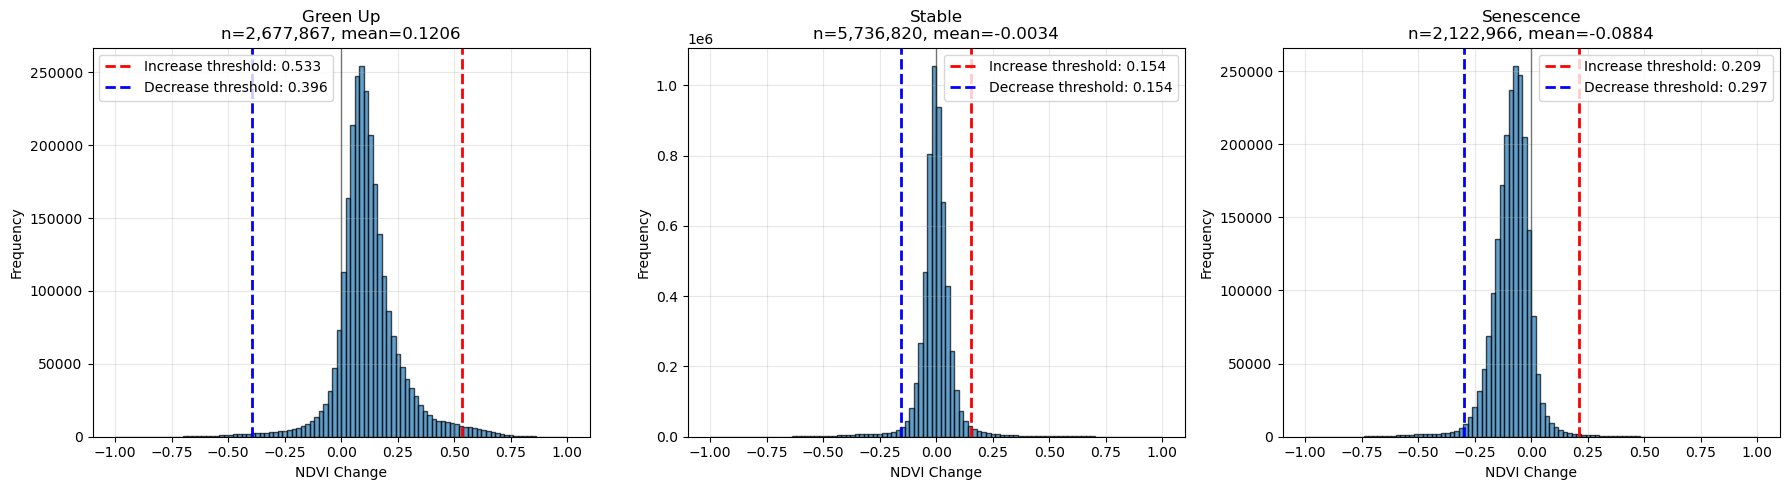

✓ Visualization saved


In [17]:
# Visualize temporal difference distributions by category
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (category, diffs) in enumerate(diffs_by_category.items()):
    if len(diffs) == 0:
        continue
    
    ax = axes[idx]
    
    # Histogram
    ax.hist(diffs, bins=100, alpha=0.7, edgecolor='black', range=(-1, 1))
    
    # Add threshold lines
    if category in thresholds:
        inc_thresh = thresholds[category]['increase']
        dec_thresh = thresholds[category]['decrease']
        
        if not np.isnan(inc_thresh):
            ax.axvline(inc_thresh, color='red', linestyle='--', linewidth=2, 
                      label=f'Increase threshold: {inc_thresh:.3f}')
        if not np.isnan(dec_thresh):
            ax.axvline(-dec_thresh, color='blue', linestyle='--', linewidth=2,
                      label=f'Decrease threshold: {dec_thresh:.3f}')
    
    ax.axvline(0, color='black', linestyle='-', linewidth=1, alpha=0.5)
    ax.set_xlabel('NDVI Change')
    ax.set_ylabel('Frequency')
    ax.set_title(f'{category.replace("_", " ").title()}\n'
                f'n={len(diffs):,}, mean={np.mean(diffs):.4f}')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(base_path / 'temporal_difference_distributions_by_category.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualization saved")

In [18]:
# Free memory - delete temporal differences (no longer needed)
import gc

print("Cleaning up memory...")
del temporal_diffs
del diffs_by_category
gc.collect()
print("Memory cleaned up - ready for filtering")

Cleaning up memory...
Memory cleaned up - ready for filtering


## 7. Apply Temporal Consistency Filtering

For each mosaic:
- Compare to previous period (if exists)
- Compare to next period (if exists)
- For first period of each year, compare to other years
- Apply appropriate thresholds based on time period

In [19]:
def get_transition_category(period1, period2, year):
    """
    Get the phenological category for a transition between two periods.
    Looks up from pre-calculated categories.
    """
    if (year, period1, period2) in transition_categories:
        return transition_categories[(year, period1, period2)]
    return None

print("Helper function defined")

Helper function defined


In [20]:
def apply_temporal_filter(current, previous, next_period, year, period_name, next_period_name):
    """
    Apply temporal consistency filter to current mosaic.
    
    Args:
        current: Current period mosaic
        previous: Previous period mosaic (or None if first period)
        next_period: Next period mosaic (or None if last period)
        year: Current year
        period_name: Name of current period
        next_period_name: Name of next period (for categorization)
    
    Returns:
        Filtered mosaic, filtered_count, remaining_pixels
    """
    filtered = current.copy()
    total_pixels = np.sum(~np.isnan(current))
    
    if total_pixels == 0:
        return filtered, 0, 0
    
    # Track what gets filtered
    filter_mask = np.zeros(current.shape, dtype=bool)
    
    # === TEMPORAL CONSISTENCY FILTER ===
    
    # Compare to previous period
    if previous is not None:
        # Determine category for this transition
        # Need to find the period name before current
        prev_period_name = None
        year_periods = [p[0] for p in periods if p[0] in mosaics[year]]
        for i, p in enumerate(year_periods):
            if p == period_name and i > 0:
                prev_period_name = year_periods[i-1]
                break
        
        if prev_period_name:
            category = get_transition_category(prev_period_name, period_name, year)
            
            if category and category in thresholds:
                inc_thresh = thresholds[category]['increase']
                dec_thresh = thresholds[category]['decrease']
                
                diff_prev = current - previous
                
                # Flag increases beyond threshold
                if not np.isnan(inc_thresh):
                    filter_mask |= (diff_prev > inc_thresh)
                
                # Flag decreases beyond threshold
                if not np.isnan(dec_thresh):
                    filter_mask |= (diff_prev < -dec_thresh)
    
    # Compare to next period
    if next_period is not None and next_period_name:
        category = get_transition_category(period_name, next_period_name, year)
        
        if category and category in thresholds:
            inc_thresh = thresholds[category]['increase']
            dec_thresh = thresholds[category]['decrease']
            
            diff_next = next_period - current
            
            # Flag if NEXT period has unrealistic change
            if not np.isnan(inc_thresh):
                filter_mask |= (diff_next > inc_thresh)
            
            if not np.isnan(dec_thresh):
                filter_mask |= (diff_next < -dec_thresh)
    
    # Apply filter
    filtered[filter_mask] = np.nan
    
    # Count filtered pixels
    filtered_count = np.sum(filter_mask & ~np.isnan(current))
    remaining_pixels = np.sum(~np.isnan(filtered))
    
    return filtered, filtered_count, remaining_pixels

print("Filtering function defined (temporal consistency only)")

Filtering function defined (temporal consistency only)


In [22]:
print("Applying temporal consistency filtering...\n")

# Store filtered mosaics
filtered_mosaics = {}  # {year: {period_name: filtered_array}}
filtering_stats = []  # Track statistics

# Output metadata
output_profile = {
    'driver': 'GTiff',
    'dtype': 'float32',
    'nodata': np.nan,
    'width': reference_width,
    'height': reference_height,
    'count': 1,
    'crs': target_crs,
    'transform': reference_transform,
    'compress': 'lzw',
    'tiled': True,
    'blockxsize': 256,
    'blockysize': 256
}

for year in years:
    print(f"Filtering {year}...")
    filtered_mosaics[year] = {}
    year_path = ndvi_filtered_path / str(year)
    
    year_periods = [p[0] for p in periods if p[0] in mosaics[year]]
    
    for i, period_name in enumerate(year_periods):
        print(f"  {period_name}...", end=' ')
        
        current = mosaics[year][period_name]
        
        # Get previous period (within year)
        previous = mosaics[year][year_periods[i-1]] if i > 0 else None
        
        # Get next period (within year)
        next_period = mosaics[year][year_periods[i+1]] if i < len(year_periods)-1 else None
        next_period_name = year_periods[i+1] if i < len(year_periods)-1 else None
        
        # Apply temporal filter
        filtered, filtered_count, remaining = apply_temporal_filter(
            current, previous, next_period, year, period_name, next_period_name
        )
        
        # Save to disk immediately (don't keep in memory)
        output_file = year_path / f'mosaic_{year}_{period_name}.tif'
        with rasterio.open(output_file, 'w', **output_profile) as dst:
            dst.write(filtered, 1)
        
        # Track stats
        original_pixels = np.sum(~np.isnan(current))
        pct_removed = 100 * filtered_count / original_pixels if original_pixels > 0 else 0
        
        filtering_stats.append({
            'year': year,
            'period': period_name,
            'original_pixels': original_pixels,
            'filtered_pixels': filtered_count,
            'remaining_pixels': remaining,
            'pct_removed': pct_removed
        })
        
        print(f"Removed {filtered_count:,} pixels ({pct_removed:.2f}%), {remaining:,} remaining ✓ saved")
        
        # Free memory - don't accumulate filtered mosaics
        del filtered
    
    print()

print("✓ Filtering complete - all mosaics saved to disk\n")

Applying temporal consistency filtering...

Filtering 2022...
  May01-15... Removed 16,670,884 pixels (34.36%), 31,848,062 remaining ✓ saved
  May16-31... Removed 17,148,427 pixels (35.27%), 31,473,767 remaining ✓ saved
  Jun01-15... Removed 4,229,989 pixels (10.62%), 35,596,766 remaining ✓ saved
  Jun16-30... Removed 1,568,923 pixels (3.20%), 47,489,207 remaining ✓ saved
  Jul01-15... Removed 1,658,741 pixels (3.37%), 47,593,700 remaining ✓ saved
  Jul16-31... Removed 1,699,413 pixels (3.40%), 48,304,362 remaining ✓ saved
  Aug01-15... Removed 878,402 pixels (1.77%), 48,759,788 remaining ✓ saved
  Aug16-31... Removed 569,221 pixels (1.14%), 49,374,950 remaining ✓ saved
  Sep01-15... Removed 1,091,885 pixels (2.20%), 48,503,043 remaining ✓ saved
  Sep16-30... Removed 1,056,691 pixels (2.12%), 48,805,717 remaining ✓ saved
  Oct01-15... Removed 245,713 pixels (0.50%), 49,163,329 remaining ✓ saved

Filtering 2023...
  May01-15... Removed 261,062 pixels (0.53%), 49,189,502 remaining ✓ save

In [25]:
# Diagnostic for June 01-15
period_name = 'Jun01-15'
year = 2022

current = mosaics[year][period_name]
previous = mosaics[year]['May16-31']
next_period = mosaics[year]['Jun16-30']

print(f"=== {period_name} {year} Diagnostics ===\n")

# Current period stats
print(f"Current period NDVI:")
print(f"  Mean: {np.nanmean(current):.3f}")
print(f"  5th-95th: [{np.nanpercentile(current, 5):.3f}, {np.nanpercentile(current, 95):.3f}]")
print(f"  10th-90th: [{np.nanpercentile(current, 10):.3f}, {np.nanpercentile(current, 90):.3f}]")

# Temporal changes
diff_prev = current - previous
diff_next = next_period - current

print(f"\nTemporal changes:")
print(f"  May16-31 → Jun01-15:")
print(f"    Mean change: {np.nanmean(diff_prev):.3f}")
print(f"    95th percentile of increases: {np.nanpercentile(diff_prev[diff_prev > 0], 95):.3f}")
print(f"    98th percentile of increases: {np.nanpercentile(diff_prev[diff_prev > 0], 98):.3f}")
print(f"    95th percentile of decreases: {np.nanpercentile(np.abs(diff_prev[diff_prev < 0]), 95):.3f}")

print(f"  Jun01-15 → Jun16-30:")
print(f"    Mean change: {np.nanmean(diff_next):.3f}")

# What are the thresholds being used?
prev_category = get_transition_category('May16-31', 'Jun01-15', year)
next_category = get_transition_category('Jun01-15', 'Jun16-30', year)

print(f"\nThresholds used:")
print(f"  Previous transition (May16-31 → Jun01-15) category: {prev_category}")
if prev_category and prev_category in thresholds:
    print(f"    Increase threshold: {thresholds[prev_category]['increase']:.3f}")
    print(f"    Decrease threshold: {thresholds[prev_category]['decrease']:.3f}")

print(f"  Next transition (Jun01-15 → Jun16-30) category: {next_category}")
if next_category and next_category in thresholds:
    print(f"    Increase threshold: {thresholds[next_category]['increase']:.3f}")
    print(f"    Decrease threshold: {thresholds[next_category]['decrease']:.3f}")

=== Jun01-15 2022 Diagnostics ===

Current period NDVI:
  Mean: 0.500
  5th-95th: [0.130, 0.748]
  10th-90th: [0.265, 0.698]

Temporal changes:
  May16-31 → Jun01-15:
    Mean change: 0.159
    95th percentile of increases: 0.606
    98th percentile of increases: 0.684
    95th percentile of decreases: 0.417
  Jun01-15 → Jun16-30:
    Mean change: 0.130

Thresholds used:
  Previous transition (May16-31 → Jun01-15) category: green_up
    Increase threshold: 0.533
    Decrease threshold: 0.396
  Next transition (Jun01-15 → Jun16-30) category: green_up
    Increase threshold: 0.533
    Decrease threshold: 0.396


In [27]:
# Filtering statistics
filtering_df = pd.DataFrame(filtering_stats)

print("="*80)
print("FILTERING STATISTICS")
print("="*80)
print("\nOverall statistics:")
print(f"  Total original pixels: {filtering_df['original_pixels'].sum():,}")
print(f"  Total filtered pixels: {filtering_df['filtered_pixels'].sum():,}")
print(f"  Overall removal rate: {filtering_df['filtered_pixels'].sum() / filtering_df['original_pixels'].sum() * 100:.3f}%")

print("\nBy year:")
year_stats = filtering_df.groupby('year').agg({
    'filtered_pixels': 'sum',
    'original_pixels': 'sum',
    'pct_removed': 'mean'
}).round(3)
print(year_stats)

print("\nBy period:")
period_stats = filtering_df.groupby('period').agg({
    'filtered_pixels': 'sum',
    'original_pixels': 'sum',
    'pct_removed': 'mean'
}).round(3)
print(period_stats)

print("="*80)

FILTERING STATISTICS

Overall statistics:
  Total original pixels: 1,279,808,623
  Total filtered pixels: 72,813,585
  Overall removal rate: 5.689%

By year:
      filtered_pixels  original_pixels  pct_removed
year                                               
2022         46818289        533730980        8.904
2023         14230625        441399224        3.233
2024         11764671        304678419        3.689

By period:
          filtered_pixels  original_pixels  pct_removed
period                                                 
Aug01-15          3659088        144778954        2.568
Aug16-31           950611         98818491        0.960
Jul01-15          7631336        143870646        5.292
Jul16-31          3595648         99928634        3.598
Jun01-15          5495405        135892022        4.416
Jun16-30          5604231         98300397        5.696
May01-15         16931946        145538865       11.629
May16-31         17148427         48622194       17.634
Oct01-15  

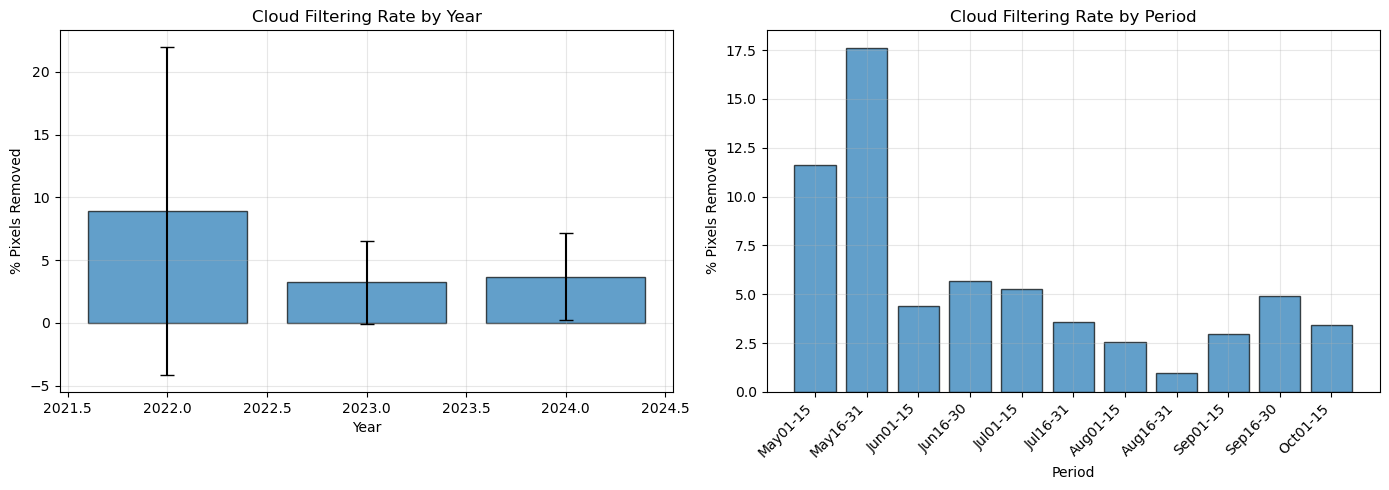

✓ Visualization saved


In [28]:
# Visualize filtering statistics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# By year
ax = axes[0]
year_stats = filtering_df.groupby('year')['pct_removed'].agg(['mean', 'std'])
ax.bar(year_stats.index, year_stats['mean'], yerr=year_stats['std'], 
       capsize=5, alpha=0.7, edgecolor='black')
ax.set_xlabel('Year')
ax.set_ylabel('% Pixels Removed')
ax.set_title('Cloud Filtering Rate by Year')
ax.grid(True, alpha=0.3)

# By period
ax = axes[1]
period_order = [p[0] for p in periods]
period_stats = filtering_df.groupby('period')['pct_removed'].mean().reindex(period_order)
ax.bar(range(len(period_stats)), period_stats.values, alpha=0.7, edgecolor='black')
ax.set_xlabel('Period')
ax.set_ylabel('% Pixels Removed')
ax.set_title('Cloud Filtering Rate by Period')
ax.set_xticks(range(len(period_stats)))
ax.set_xticklabels(period_stats.index, rotation=45, ha='right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(base_path / 'filtering_statistics.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualization saved")

## 8. Save Filtered Mosaics

Save filtered mosaics to disk, overwriting existing files.

In [29]:
# Final verification - check that saved files have correct dimensions
print("\nVerifying saved files...")

for year in years:
    year_path = ndvi_filtered_path / str(year)
    files = sorted(year_path.glob('mosaic_*.tif'))
    
    shapes = []
    for f in files:
        with rasterio.open(f) as src:
            shapes.append(src.shape)
    
    unique_shapes = set(shapes)
    print(f"  {year}: {len(files)} files, {len(unique_shapes)} unique shape(s)")
    
    if len(unique_shapes) == 1 and list(unique_shapes)[0] == reference_shape:
        print(f"    ✓ All files have correct dimensions: {reference_shape}")
    else:
        print(f"    ✗ ERROR: Inconsistent dimensions!")
        for shape in unique_shapes:
            print(f"      {shape}")

print("\n" + "="*80)
print("PHASE 2 COMPLETE")
print("="*80)
print(f"Filtered mosaics saved to: {ndvi_filtered_path}")
print(f"All mosaics aligned on common {reference_shape} grid")
print(f"Overall cloud removal rate: {filtering_df['filtered_pixels'].sum() / filtering_df['original_pixels'].sum() * 100:.3f}%")
print("\nReady for Phase 3!")
print("="*80)


Verifying saved files...
  2022: 11 files, 1 unique shape(s)
    ✓ All files have correct dimensions: (22148, 22702)
  2023: 9 files, 1 unique shape(s)
    ✓ All files have correct dimensions: (22148, 22702)
  2024: 8 files, 1 unique shape(s)
    ✓ All files have correct dimensions: (22148, 22702)

PHASE 2 COMPLETE
Filtered mosaics saved to: S:\8band_processing_workflow\ndvi_filtered
All mosaics aligned on common (22148, 22702) grid
Overall cloud removal rate: 5.689%

Ready for Phase 3!
